# Treinando um agente para jogar **Breakout** (Atari) com PPO

**Disciplina:** Aprendizado por Reforço — IBMEC 2026/2 · **Professor:** Pedro Calais
**Atividade Complementar Final** · **Aluno(s):** _preencher_

Este notebook é a entrega (item **m**). O código fica no pacote `src/breakout_rl/`, que este
notebook importa. O treino longo (~4 h num Mac M3) roda **fora** do notebook pelo
`scripts/train_overnight.sh`, com checkpoints e retomada. Aqui carregamos os resultados.

| Item | Seção |
|---|---|
| a, b | 1. Jogo escolhido |
| c, d, e | 2. Ambiente, ações e recompensas |
| f | 3. Política aleatória |
| h | 4. Ajustes em relação ao código base |
| g | 5. Treinamento e TensorBoard |
| i | 6. Tempo até uma política minimamente inteligente |
| j | 7. Parâmetros da rede |
| k, l | 8. Agente treinado e análise das jogadas |

## 0. Setup
Funciona localmente (`make setup`) e no Google Colab (clona o repositório).

In [1]:
import os, sys, json
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clona e instala
    if not Path("rl-breakout-ppo").exists():
        !git clone -q https://github.com/vnevesl/rl-breakout-ppo.git
    os.chdir("rl-breakout-ppo")
    !pip install -q -e .
else:  # local: o notebook fica em notebooks/
    if Path.cwd().name == "notebooks":
        os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))
ROOT = Path.cwd()
RUN = ROOT / "runs" / "ppo_breakout"            # artefatos do treino (local, fora do git)
RESULTS = ROOT / "reports" / "results"            # resultados versionados
MODEL = RUN / "best_model" / "best_model.zip"
if not MODEL.exists():                            # ex.: no Colab, usa o modelo versionado
    MODEL = ROOT / "reports" / "models" / "best_model.zip"
print("Raiz do projeto:", ROOT, "| modelo:", MODEL.relative_to(ROOT))

Raiz do projeto: /Users/vitorneves/Desktop/rl-breakout-ppo | modelo: runs/ppo_breakout/best_model/best_model.zip


In [2]:
from IPython.display import Video, Image, Markdown, display
import pandas as pd

from breakout_rl.config import ExperimentConfig
from breakout_rl.envs import describe_env

cfg = ExperimentConfig.from_yaml("configs/ppo_breakout.yaml")

## 1. Jogo escolhido (a, b)

**a) Breakout** (`ALE/Breakout-v5`, Atari 2600, 1978). O jogador controla uma raquete na base da
tela e rebate uma bola contra um muro de tijolos coloridos. Cada tijolo destruído dá pontos.
O objetivo é destruir o muro sem deixar a bola passar pela raquete.

**b) Jogando você mesmo:** `make play` (ou `python -m breakout_rl.play`). Use ← → para mover e
ESPAÇO (FIRE) para lançar a bola.

> _Impressões ao jogar (preencher):_ ex.: a bola acelera depois de alguns toques e ao atingir
> as fileiras de cima; a raquete encolhe quando a bola chega ao teto; é preciso apertar FIRE a
> cada vida perdida.

## 2. Ambiente, ações e recompensas (c, d, e)

In [3]:
info = describe_env("ALE/Breakout-v5")
info

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


{'env_id': 'ALE/Breakout-v5',
 'observation_space': 'Box(0, 255, (210, 160, 3), uint8)',
 'action_space': 'Discrete(4)',
 'n_actions': 4,
 'action_meanings': {0: 'NOOP', 1: 'FIRE', 2: 'RIGHT', 3: 'LEFT'},
 'frameskip': 4,
 'repeat_action_probability': 0.25,
 'max_episode_steps': None,
 'lives': 5}

**c) Ambiente.** Vem do Arcade Learning Environment (ALE) via Gymnasium.
- **Observação crua:** imagem RGB `210×160×3` (`Box(0, 255, (210,160,3), uint8)`). Também existem
  as versões `grayscale` e `ram` (128 bytes da memória do Atari).
- **Dinâmica no v5:** `frameskip=4` (cada ação dura 4 frames) e `repeat_action_probability=0.25`
  ("sticky actions": 25% de chance de repetir a ação anterior, o que dá estocasticidade).
- **Episódio:** 5 vidas. Termina quando as vidas acabam (ou no limite de 108.000 frames).
- **Pré-processamento usado no treino** (`AtariWrapper` do SB3 + `VecFrameStack`):
  até 30 no-ops aleatórios no início; ação repetida por 4 frames (max dos 2 últimos);
  FIRE automático no reset; escala de cinza 84×84 ("se livre de pixels inúteis");
  perda de vida tratada como fim de episódio no treino; recompensa clipada em {-1, 0, +1};
  **4 frames empilhados** para que a rede perceba a direção e a velocidade da bola.
  A observação final tem formato `84×84×4`.

**d) Ações: 4 ações discretas** (`Discrete(4)`, conjunto mínimo):

| id | ação | efeito |
|---|---|---|
| 0 | NOOP | não faz nada |
| 1 | FIRE | lança a bola (necessário no início e após cada vida perdida) |
| 2 | RIGHT | move a raquete para a direita |
| 3 | LEFT | move a raquete para a esquerda |

Com `full_action_space=True` o ALE expõe as 18 ações do controle do Atari, mas as 14 extras são
redundantes neste jogo.

**e) Recompensas.** O agente ganha pontos ao destruir tijolos, e o valor depende da cor/fileira
(manual do Atari): as **2 fileiras de baixo (azul, verde) valem 1**, as **2 do meio (amarela,
laranja) valem 4** e as **2 de cima (laranja-escuro, vermelha) valem 7**. Um muro completo vale
432 pontos e, ao limpá-lo, surge um segundo muro (máximo teórico de 864). Não há recompensa
negativa: perder a bola só custa uma vida, o que encerra a partida mais cedo e reduz a pontuação
futura.
No treino, a recompensa é **clipada** para +1 por tijolo, para estabilizar o aprendizado. Os
gráficos e as avaliações mostram a **pontuação real** do jogo.

## 3. Política aleatória, sem aprendizado (f)

In [4]:
from breakout_rl.record import record
from breakout_rl.evaluate import evaluate

random_video = Path("reports/videos/random_policy.mp4")
if not random_video.exists():
    record("random", random_video, cfg.env, episodes=3)
display(Video(str(random_video), embed=True, width=320))

In [5]:
rand_path = RESULTS / "eval_random.json"
rand = json.loads(rand_path.read_text()) if rand_path.exists() else evaluate("random", cfg.env, episodes=20)
print(f"Política aleatória: {rand['mean']:.1f} ± {rand['std']:.1f} pontos por partida "
      f"(min {rand['min']:.0f}, max {rand['max']:.0f}) em 20 partidas")

Política aleatória: 1.7 ± 1.8 pontos por partida (min 0, max 7) em 20 partidas


A política aleatória quase nunca acerta a bola: perde as 5 vidas em poucos segundos e faz ~1–2
pontos por partida. Esse é o *baseline* que o agente precisa superar.

## 4. Ajustes em relação ao código base (h)

O código base (Freeway, "jogo da galinha") treinava PPO com 1 ambiente, sem empilhar frames, por
50 mil passos. O Freeway é fácil: basta "andar para cima" com timing. O Breakout exige
**rastrear a bola** e **planejar a posição da raquete**, então ajustamos o seguinte (valores
inspirados nos hiperparâmetros de Atari do RL Baselines3 Zoo):

| Parâmetro | Código base | Este trabalho | Por quê |
|---|---|---|---|
| `total_timesteps` | 50.000 | **10.000.000** | Breakout precisa de muito mais experiência |
| ambientes paralelos (`n_envs`) | 1 | **8** | mais experiência variada por atualização e por segundo |
| frame stack | nenhum | **4** | 1 frame não mostra a direção/velocidade da bola |
| `frameskip` do `gym.make` | 4 (padrão v5) | **1** | o `AtariWrapper` já pula 4; com os dois juntos, o agente via 1 a cada 16 frames |
| `repeat_action_probability` | 0.25 | **0.0** | igual ao `BreakoutNoFrameskip-v4` dos benchmarks |
| `n_steps` (por env) | 2048 | **128** | 128×8 = 1024 passos por atualização, atualizações mais frequentes |
| `batch_size` | 256 | 256 | igual |
| `n_epochs` | 10 | **4** | menos reuso do mesmo lote evita políticas instáveis |
| `learning_rate` | 2.5e-4 constante | **2.5e-4 → 0 (linear)** | passos grandes no início, ajuste fino no fim |
| `clip_range` | 0.2 | **0.1 → 0 (linear)** | atualizações de política mais conservadoras |
| `ent_coef` | 0.0 | **0.01** | bônus de entropia mantém a exploração |
| `device` | cpu | **mps** (GPU Apple) | ~760 contra ~255 passos/s no M3, cerca de 3× mais rápido |

Esses valores estão versionados em `configs/ppo_breakout.yaml`. A configuração do professor
aplicada ao Breakout fica em `configs/baseline_professor.yaml`, para comparação.

In [6]:
import yaml
print(yaml.safe_dump(cfg.to_dict(), sort_keys=False, allow_unicode=True))

name: ppo_breakout
env:
  env_id: ALE/Breakout-v5
  n_envs: 8
  frame_stack: 4
  frameskip: 1
  repeat_action_probability: 0.0
  terminal_on_life_loss: true
  clip_reward: true
  vec_env: subproc
ppo:
  policy: CnnPolicy
  n_steps: 128
  batch_size: 256
  n_epochs: 4
  learning_rate: 0.00025
  lr_schedule: linear
  clip_range: 0.1
  clip_schedule: linear
  gamma: 0.99
  gae_lambda: 0.95
  ent_coef: 0.01
  vf_coef: 0.5
  max_grad_norm: 0.5
train:
  total_timesteps: 10000000
  seed: 42
  device: auto
  checkpoint_freq: 250000
  eval_freq: 250000
  eval_episodes: 5
  smart_threshold: 30



## 5. Treinamento e TensorBoard (g)

O treino roda em segundo plano, fora do notebook:

```bash
./scripts/train_overnight.sh        # caffeinate + nohup + --resume; checkpoint a cada 250k passos
tail -f runs/ppo_breakout/train.log
./scripts/tensorboard.sh            # http://localhost:6006
./scripts/stop_training.sh          # para salvando checkpoint; rode o 1º comando para retomar
```

Para um teste rápido dentro do notebook, descomente a célula abaixo (≈1 min).

In [7]:
# from breakout_rl.train import train
# smoke = ExperimentConfig.from_yaml("configs/smoke.yaml")
# train(smoke)

**Resultado do treino:** 10 milhões de passos (≈ 40 milhões de frames) em **3,7 h** num MacBook
Air M3 (GPU via MPS, ~730 passos/s). A pontuação média subiu de forma quase contínua, de 1,7
para **374 pontos** (média das últimas 100 partidas ao final). A curva ainda subia no fim, então
mais passos provavelmente renderiam mais pontos.

**Print do TensorBoard:** depois do treino, abra o TensorBoard, tire o print do painel
`rollout/ep_rew_mean` e salve em `reports/figures/tensorboard.png`.
Métricas principais:
- `rollout/ep_rew_mean`: pontuação média por partida (últimas 100). É a curva de aprendizado.
- `eval/mean_reward`: pontuação na avaliação periódica (a cada 250 mil passos).
- `train/entropy_loss`: cai conforme a política fica mais confiante.
- `train/approx_kl` e `train/clip_fraction`: tamanho das atualizações do PPO. Vão a ~0 no fim
  porque a taxa de aprendizado e o clip decaem linearmente até zero.

In [8]:
%load_ext tensorboard
%tensorboard --logdir runs

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

Salvo: reports/figures/ppo_breakout_curves.png


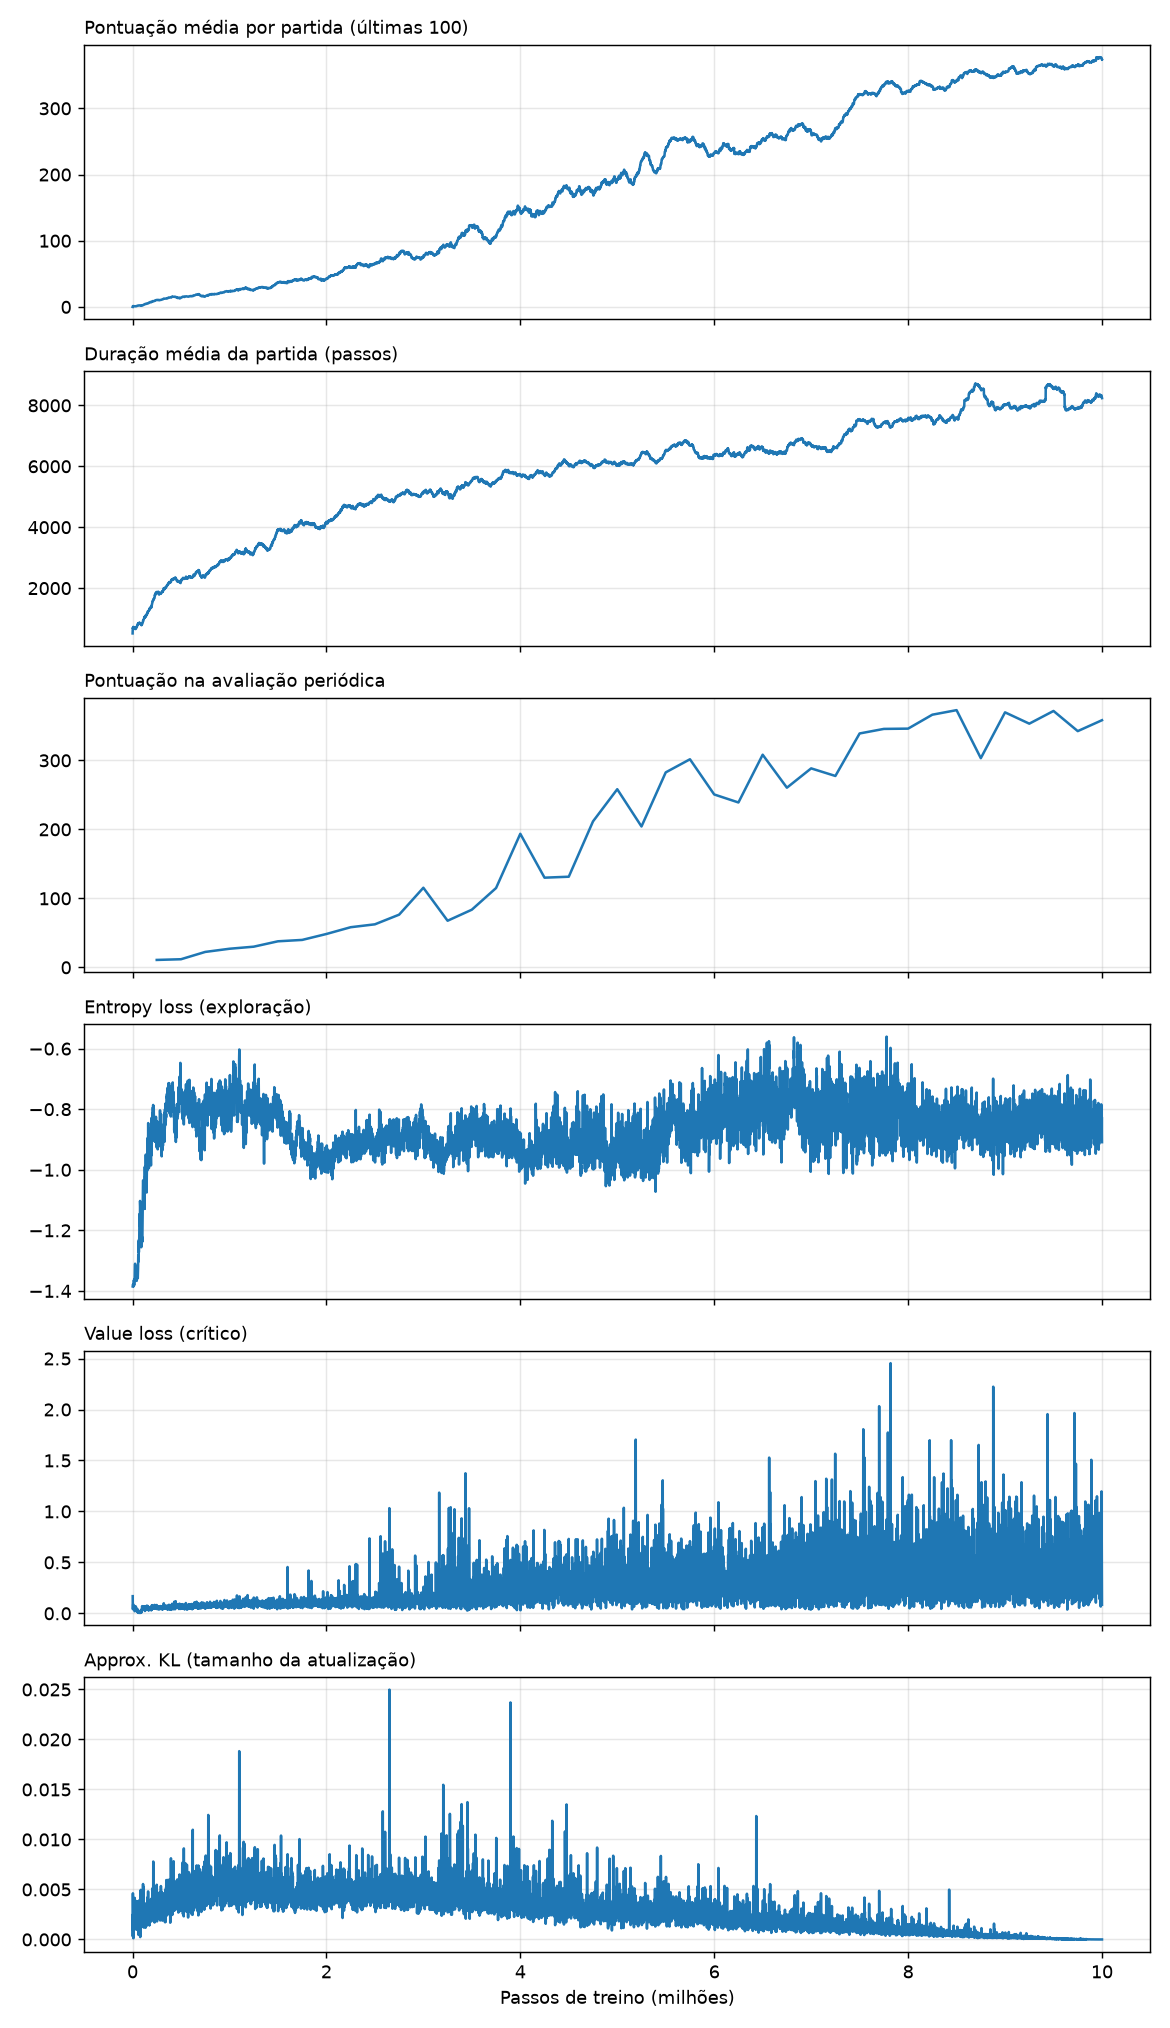

In [9]:
tb_png = Path("reports/figures/tensorboard.png")
if tb_png.exists():
    display(Image(str(tb_png)))

from breakout_rl.plots import plot_run
curves = Path("reports/figures/ppo_breakout_curves.png")
if RUN.exists():
    plot_run(RUN, Path("reports/figures"))
if curves.exists():
    display(Image(str(curves)))
else:
    print("Treino ainda não executado.")

## 6. Quanto tempo até uma política minimamente inteligente? (i)

In [10]:
ms_path = RUN / "milestones.json"
if not ms_path.exists():
    ms_path = RESULTS / "milestones.json"
if ms_path.exists():
    ms = json.loads(ms_path.read_text())
    df = pd.DataFrame(ms["milestones"]).T.rename_axis("média ≥").reset_index()
    display(df)
    print(f"Tempo total de treino: {ms['elapsed_seconds']/3600:.2f} h, "
          f"{ms.get('last_timesteps', 0):,} passos")
else:
    print("Rode o treino primeiro.")

,média ≥,timesteps,wall_clock_hours,mean_reward_last_100
0,5,151200.0,0.068,5.03
1,10,239032.0,0.115,10.00
2,20,881848.0,0.385,20.08
3,30,1326680.0,0.548,30.00
4,50,2112040.0,0.821,50.01
5,100,3353024.0,1.256,100.55
6,200,5036616.0,1.856,200.06
7,300,7409664.0,2.814,300.41


Tempo total de treino: 3.72 h, 10,000,384 passos


**Critério de "minimamente inteligente":** média ≥ **30 pontos** por partida nas últimas 100
partidas, ou seja, ~15× a política aleatória. Nesse nível o agente já segue a bola com a
raquete de forma consistente.

**Resposta:** o agente atingiu média 30 com **1,33 milhão de passos, em ~33 minutos** de treino
num MacBook Air M3 (GPU via MPS).

| Média (últimas 100 partidas) | Passos | Tempo |
|---|---|---|
| 10 | 0,24 M | 7 min |
| **30 (minimamente inteligente)** | **1,33 M** | **33 min** |
| 100 | 3,35 M | 1 h 15 |
| 200 | 5,04 M | 1 h 51 |
| 300 | 7,41 M | 2 h 49 |
| 374 (final) | 10,0 M | 3 h 43 |

## 7. Quantos parâmetros tem a rede? (j)

In [11]:
from stable_baselines3 import PPO
from breakout_rl.model_info import summarize

model_path = MODEL
if model_path.exists():
    policy = PPO.load(model_path, device="cpu").policy
else:
    from breakout_rl.model_info import _fresh_policy
    policy = _fresh_policy()
s = summarize(policy)
display(pd.DataFrame(s["layers"], columns=["camada", "shape", "parâmetros"]))
print(f"TOTAL: {s['total']:,} parâmetros")

,camada,shape,parâmetros
0,features_extractor.cnn.0.weight,"(32, 4, 8, 8)",8192
1,features_extractor.cnn.0.bias,"(32,)",32
2,features_extractor.cnn.2.weight,"(64, 32, 4, 4)",32768
3,features_extractor.cnn.2.bias,"(64,)",64
4,features_extractor.cnn.4.weight,"(64, 64, 3, 3)",36864
5,features_extractor.cnn.4.bias,"(64,)",64
6,features_extractor.linear.0.weight,"(512, 3136)",1605632
7,features_extractor.linear.0.bias,"(512,)",512
8,action_net.weight,"(4, 512)",2048
9,action_net.bias,"(4,)",4


TOTAL: 1,686,693 parâmetros


A `CnnPolicy` do SB3 é a "Nature CNN" (Mnih et al., 2015), compartilhada entre ator e crítico:

| Bloco | Camada | Parâmetros |
|---|---|---|
| Extrator | Conv 8×8, 32 filtros, stride 4 (entrada 4 canais) | 8.224 |
| | Conv 4×4, 64 filtros, stride 2 | 32.832 |
| | Conv 3×3, 64 filtros, stride 1 | 36.928 |
| | Linear 3136 → 512 | 1.606.144 |
| Ator (`action_net`) | Linear 512 → 4 (uma saída por ação) | 2.052 |
| Crítico (`value_net`) | Linear 512 → 1 (V(s)) | 513 |
| **Total** | | **1.686.693** |

95% dos parâmetros estão na camada densa que liga as convoluções às 512 features.

## 8. Agente após o treinamento (k, l)

Usamos o `best_model.zip`, que é o checkpoint com a melhor avaliação periódica (8,5 M passos).
O vídeo principal usa a política **estocástica** (amostra a ação pelas probabilidades da rede),
que é o mesmo modo das avaliações. Mais abaixo há um vídeo da política **determinística**, que
mostra uma falha importante.

In [12]:
trained_video = Path("reports/videos/trained_policy.mp4")
if not trained_video.exists() and model_path.exists():
    record(str(model_path), trained_video, cfg.env, episodes=2, max_steps=10_000,
           deterministic=False)
display(Video(str(trained_video), embed=True, width=320))

In [13]:
rows = []
for name, label in [("eval_random", "Política aleatória"),
                    ("eval_best_model", "PPO best_model (8,5 M passos)"),
                    ("eval_final_model", "PPO final_model (10 M passos)")]:
    d = json.loads((RESULTS / f"{name}.json").read_text())
    rows.append({"política": label, "média": round(d["mean"], 1), "desvio": round(d["std"], 1),
                 "mín": d["min"], "máx": d["max"], "partidas": d["episodes"]})
pd.DataFrame(rows)

,política,média,desvio,mín,máx,partidas
0,Política aleatória,1.7,1.8,0.0,7.0,20
1,"PPO best_model (8,5 M passos)",355.2,37.6,285.0,423.0,20
2,PPO final_model (10 M passos),365.7,50.1,192.0,417.0,20


Em 20 partidas completas (5 vidas), o agente faz **355 ± 38 pontos**, contra **1,7** da política
aleatória (~200× mais). O `final_model` tem média parecida (366) mas é menos consistente
(mínimo 192 contra 285). Para comparação: o PPO do RL Zoo chega a ~400 com o mesmo orçamento, e
o humano de referência do paper do DQN fez ~31.

In [14]:
# Linha do tempo do vídeo: cada vida perdida, com o segundo exato no vídeo.
ev = pd.read_csv("reports/videos/trained_policy_events.csv")
display(ev[ev.event != "tijolo"])

,episode,video_time_s,step,event,reward,score
75,0,51.17,1535,perdeu_vida,0.0,291.0
79,0,58.67,1760,perdeu_vida,0.0,297.0
82,0,62.17,1865,perdeu_vida,0.0,311.0
89,0,73.40,2202,perdeu_vida,0.0,347.0
94,0,77.00,2310,perdeu_vida,0.0,363.0
112,1,96.40,581,perdeu_vida,0.0,23.0
137,1,119.47,1273,perdeu_vida,0.0,86.0
176,1,135.40,1751,perdeu_vida,0.0,313.0
178,1,138.03,1830,perdeu_vida,0.0,317.0
180,1,140.13,1893,perdeu_vida,0.0,321.0


### l) Uma jogada "inteligente" e uma "burra"

**Inteligente: o túnel (vídeo principal, partida 2, de t ≈ 121 s a 135 s).** O agente concentra
as rebatidas na lateral direita até abrir um buraco no muro (t ≈ 121 s). A bola passa pelo
buraco e fica **presa entre o muro e o teto** (t ≈ 128 s), quebrando sozinha as fileiras de
cima, que valem 7 pontos. O placar salta de 86 para 313 em ~16 s sem o agente precisar tocar na
bola. É a mesma estratégia que ficou famosa no paper do DQN da DeepMind (Mnih et al., 2015).
Ninguém a programou: ela surgiu da maximização da recompensa acumulada (γ = 0,99), porque abrir
o túnel custa pouco agora e rende muitos pontos depois.

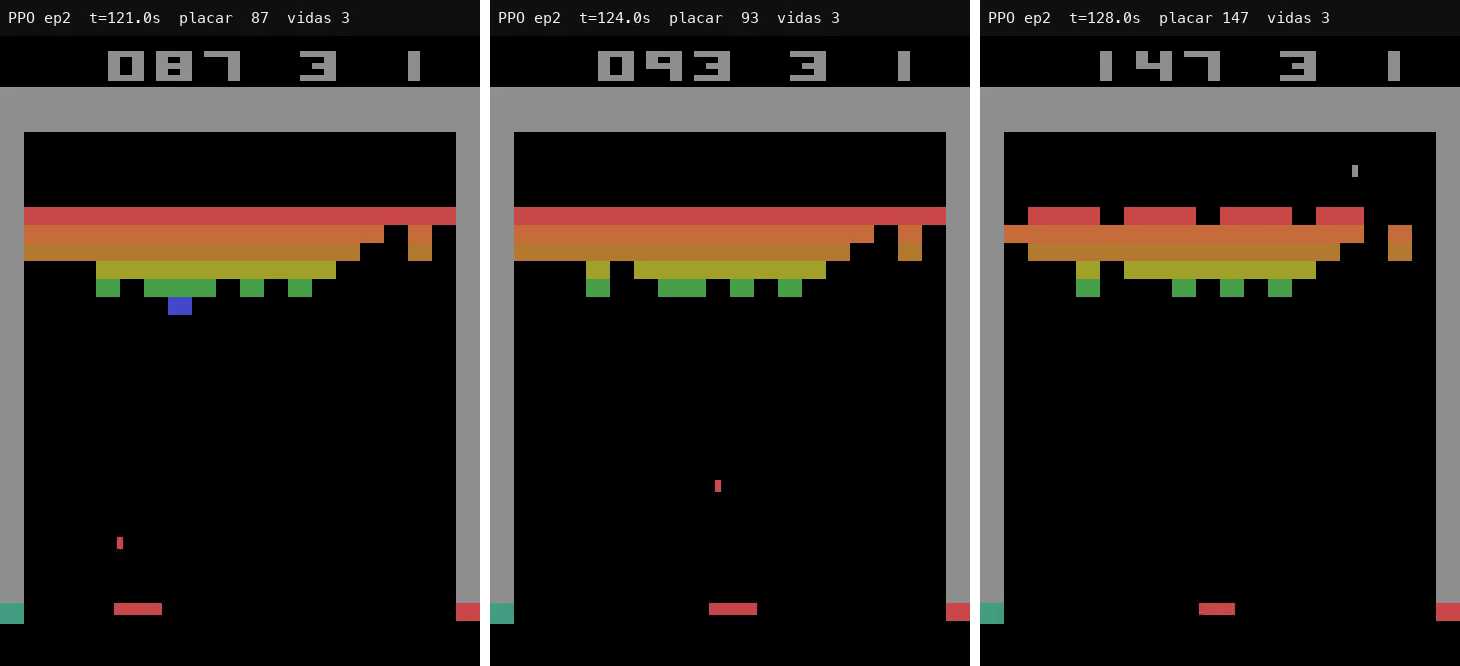

In [15]:
display(Image("reports/figures/jogada_inteligente_tunel.png"))

**Burra: esquecer de lançar a bola (vídeo determinístico, t ≈ 40 s em diante).** Depois de
perder uma vida, o agente **nunca aperta FIRE**: a raquete fica parada e a bola não volta ao
jogo. A gravação é cortada após 1.500 passos sem pontuar (`travou_sem_pontuar` no CSV).

O porquê é instrutivo. No treino, cada vida perdida **encerrava o episódio**
(`terminal_on_life_loss`) e o wrapper `FireReset` apertava FIRE sozinho no reset. O agente
nunca precisou aprender a lançar a bola, então FIRE nunca é a ação mais provável e a política
determinística (`argmax`) trava. A política estocástica escapa porque às vezes sorteia FIRE.
Possíveis correções: treinar sem `terminal_on_life_loss`, ou apertar FIRE automaticamente também
na avaliação.

Outra jogada "burra", no vídeo principal: no fim da partida 1 (t ≈ 51 s a 77 s) o agente perde
as 5 vidas em ~26 s. Depois que a bola acelera e a raquete encolhe (o que acontece quando a bola
toca o teto), ele não consegue mais acompanhar a bola. O treino teve pouca experiência nessa
fase final do jogo.

In [16]:
display(Video("reports/videos/trained_policy_deterministic.mp4", embed=True, width=320))
display(pd.read_csv("reports/videos/trained_policy_deterministic_events.csv")
          .query("event != 'tijolo'"))

,episode,video_time_s,step,event,reward,score
47,0,40.20,1206,perdeu_vida,0.0,92.0
48,0,89.83,2695,travou_sem_pontuar,0.0,92.0
136,1,195.77,3177,travou_sem_pontuar,0.0,336.0


## 9. Conclusões
- **Aprendeu de verdade:** o agente saiu de 1,7 para ~355 pontos por partida em 3,7 h de treino
  num notebook, e descobriu sozinho a estratégia do túnel.
- **Os ajustes em relação ao código base foram decisivos:** frame stacking (sem ele a rede não
  vê a direção da bola), 8 ambientes em paralelo, hiperparâmetros de Atari do RL Zoo e a
  correção do frame skip duplicado. Rodar na GPU do Mac (MPS) deixou o treino ~3× mais rápido.
- **Limitações:** (1) a política determinística trava sem apertar FIRE, um efeito colateral do
  `terminal_on_life_loss` e do `FireReset`; (2) o agente sofre na fase final, com bola rápida e
  raquete curta; (3) treinamos sem *sticky actions*, então o ambiente é determinístico e mais
  fácil que o v5 padrão.
- **Com mais tempo:** treinar mais passos (a curva ainda subia), testar com
  `repeat_action_probability=0.25`, comparar com DQN/A2C e treinar sem `terminal_on_life_loss`
  para o agente aprender a lançar a bola.

### Referências
- Stable-Baselines3: https://stable-baselines3.readthedocs.io
- RL Baselines3 Zoo, hiperparâmetros de Atari: https://github.com/DLR-RM/rl-baselines3-zoo
- ALE Breakout: https://ale.farama.org/environments/breakout/
- Schulman et al. (2017), *Proximal Policy Optimization Algorithms*
- Mnih et al. (2015), *Human-level control through deep reinforcement learning*